In [33]:
import sys
from pathlib import Path

# Add project root to sys.path so we can import from utils
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from utils.plotting import PALETTE, set_style

# Apply standard style across all plots
set_style()


# Binomial Distribution: Modeling Counts of Successes

## 1. Intuition & Motivation

Imagine you flip a fair coin 10 times. How many heads will you get?
You might get 5 heads most often, but sometimes you will get 4, 6, or even 8. Getting 0 or 10 heads is possible, but rare.

The **Binomial distribution** models exactly this phenomenon: the total number of "successes" in a fixed number of independent trials, where each trial has only two possible outcomes (success or failure) and an identical probability of success.

In probability:
- A single yes/no trial is called a **Bernoulli trial** (e.g., one coin flip).
- A **random variable** $X$ represents the numerical outcome of a random process—here, $X$ is the total count of successes observed across all trials.
- Real-world examples: number of defective items in a batch of 50, number of website visitors who convert out of 100, or number of patients responding to a treatment.


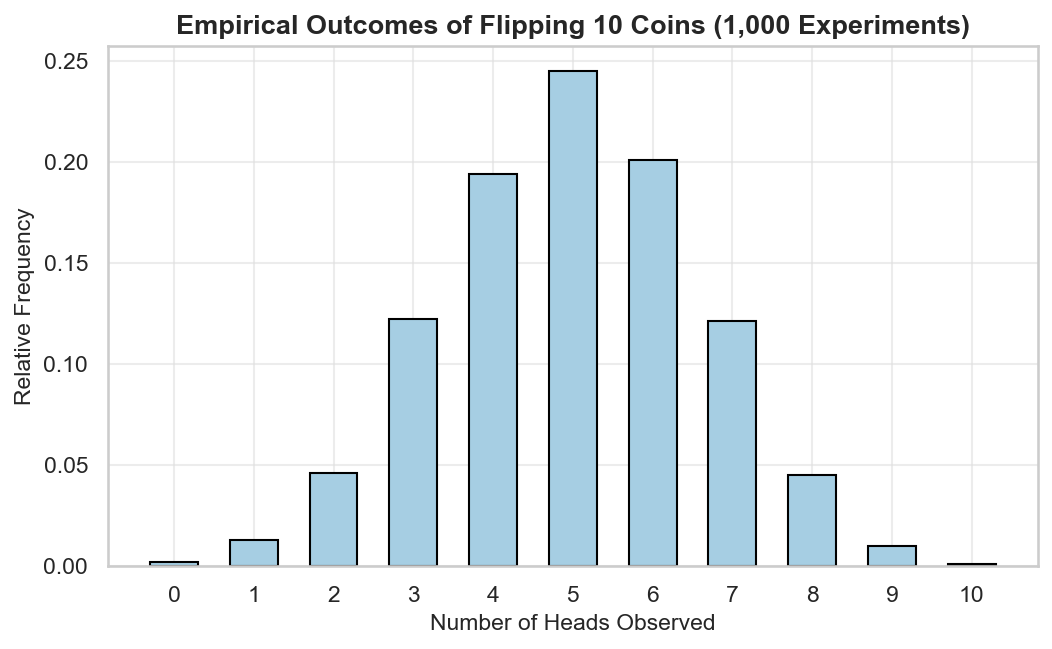

In [34]:
# Parameters
n_flips = 10  # Number of trials per experiment
p_heads = 0.5  # Probability of heads (success)
n_experiments = 1000  # Repetitions

# Seed for reproducibility
rng = np.random.default_rng(seed=42)

# Generate 1,000 experiments of 10 flips (1 = Heads, 0 = Tails)
# Shape: (1000, 10)
flips = rng.choice([0, 1], size=(n_experiments, n_flips), p=[1 - p_heads, p_heads])

# Count total heads in each experiment by summing across columns
heads_per_experiment = np.sum(flips, axis=1)

# Plot empirical distribution
counts, bins = np.histogram(heads_per_experiment, bins=np.arange(-0.5, n_flips + 1.5, 1))
plt.figure()
plt.bar(
    np.arange(0, n_flips + 1),
    counts / n_experiments,
    color=PALETTE["fill"],
    edgecolor="black",
    width=0.6,
)
plt.title(f"Empirical Outcomes of Flipping {n_flips} Coins (1,000 Experiments)")
plt.xlabel("Number of Heads Observed")
plt.ylabel("Relative Frequency")
plt.xticks(range(0, n_flips + 1))
plt.show()

## 2. Mathematical Definition

A discrete random variable $X$ follows a Binomial distribution, written as:
$$X \sim \text{Binomial}(n, p)$$

### Parameters & Support
- **$n \in \{1, 2, 3, \dots\}$**: Total number of independent trials.
- **$p \in [0, 1]$**: Probability of success on each trial ($q = 1 - p$ is failure probability).
- **Support**: The set of possible values $X$ can take: $k \in \{0, 1, 2, \dots, n\}$.

### Probability Mass Function (PMF)
For a discrete random variable, the **PMF** gives the probability that $X$ equals an exact integer outcome $k$:
$$P(X = k) = \binom{n}{k} p^k (1 - p)^{n - k}$$
where $\binom{n}{k} = \frac{n!}{k!(n - k)!}$ is the binomial coefficient.

### Cumulative Distribution Function (CDF)
The **CDF** gives the probability that $X$ takes a value less than or equal to $k$:
$$F(k) = P(X \le k) = \sum_{i=0}^{\lfloor k \rfloor} \binom{n}{i} p^i (1 - p)^{n - i}$$


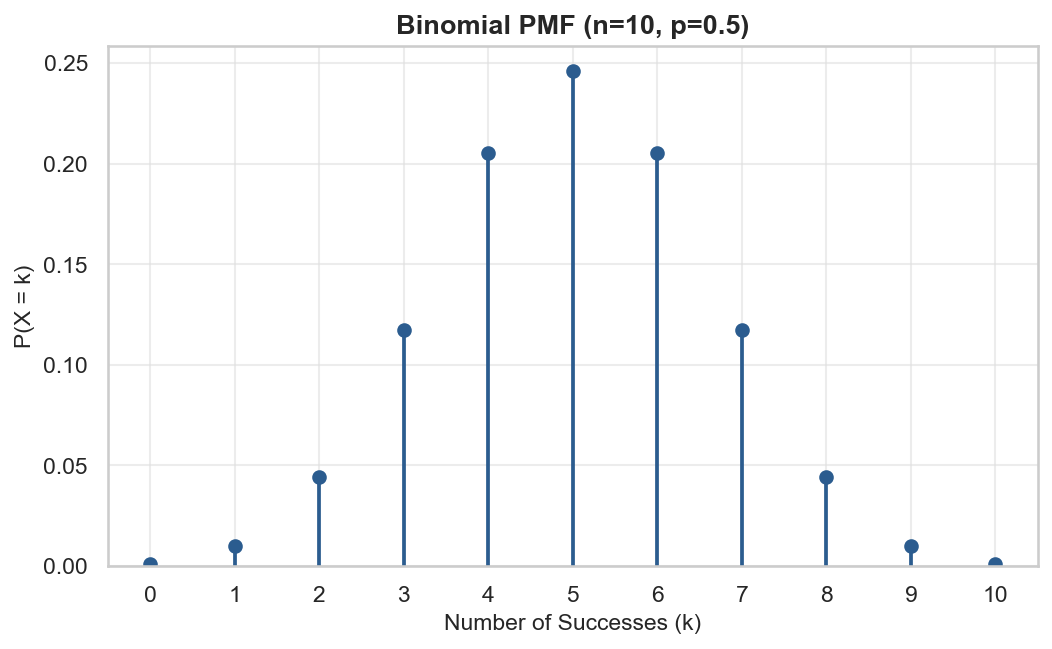

In [35]:
from utils.plotting import plot_pmf

# Distribution parameters
n = 10
p = 0.5

# All possible values in support: k = 0, 1, ..., n
k_values = np.arange(0, n + 1)

# Evaluate exact theoretical PMF: P(X = k)
pmf_values = stats.binom.pmf(k_values, n, p)

# Plot PMF using our shared helper
fig, ax = plt.subplots()
plot_pmf(
    k_values,
    pmf_values,
    title=f"Binomial PMF (n={n}, p={p})",
    xlabel="Number of Successes (k)",
    ylabel="P(X = k)",
    ax=ax,
)
plt.xticks(k_values)
plt.show()


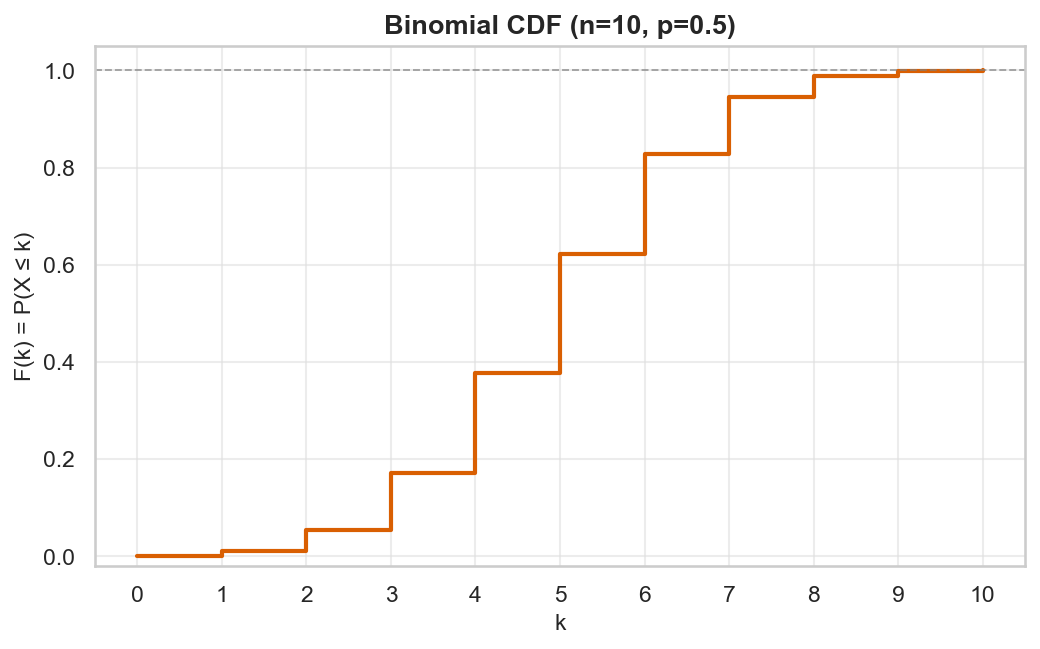

In [36]:
from utils.plotting import plot_cdf

# Evaluate exact theoretical CDF: P(X <= k)
cdf_values = stats.binom.cdf(k_values, n, p)

# Plot CDF using our shared helper with step function styling
fig, ax = plt.subplots()
plot_cdf(
    k_values,
    cdf_values,
    is_discrete=True,
    title=f"Binomial CDF (n={n}, p={p})",
    xlabel="k",
    ylabel="F(k) = P(X ≤ k)",
    ax=ax,
)
plt.xticks(k_values)
plt.show()


## 3. Key Theoretical Properties

The shape and behavior of $X \sim \text{Binomial}(n, p)$ are captured by its **moments**:

### 1. Expected Value (Mean): $\mathbb{E}[X] = \mu$
$$\mu = n p$$
The long-run average outcome if the experiment is repeated many times. Since each trial has expected value $p$, linearity of expectation gives $n \times p$.

### 2. Variance & Standard Deviation: $\text{Var}(X) = \sigma^2$, $\text{SD}(X) = \sigma$
$$\sigma^2 = n p (1 - p), \quad \sigma = \sqrt{n p (1 - p)}$$
Measures the dispersion around the mean. Notice variance is maximized when $p = 0.5$ (maximum uncertainty).

### 3. Skewness: $\gamma_1$
$$\gamma_1 = \frac{1 - 2p}{\sqrt{n p (1 - p)}}$$
Measures asymmetry:
- $p = 0.5 \implies \gamma_1 = 0$ (perfectly symmetric)
- $p < 0.5 \implies \gamma_1 > 0$ (right-skewed / positive tail)
- $p > 0.5 \implies \gamma_1 < 0$ (left-skewed / negative tail)

### 4. Excess Kurtosis: $\gamma_2$
$$\gamma_2 = \frac{1 - 6p(1 - p)}{n p (1 - p)}$$
Measures tail heaviness relative to a Normal distribution (which has excess kurtosis 0). As $n \to \infty$, $\gamma_2 \to 0$.


In [37]:
# Parameters
n = 10
p = 0.5

# Analytical calculation from formulas
mean_formula = n * p
var_formula = n * p * (1 - p)
std_formula = np.sqrt(var_formula)
skew_formula = (1 - 2 * p) / np.sqrt(n * p * (1 - p))
kurt_formula = (1 - 6 * p * (1 - p)) / (n * p * (1 - p))

# SciPy calculation ('m' = mean, 'v' = var, 's' = skew, 'k' = excess kurtosis)
mean_sp, var_sp, skew_sp, kurt_sp = stats.binom.stats(n, p, moments="mvsk")

# Display comparison
print(f"Moment               |  Formula |   SciPy")
print("-" * 42)
print(f"Mean (μ)             | {mean_formula:8.4f} | {float(mean_sp):8.4f}")
print(f"Variance (σ²)        | {var_formula:8.4f} | {float(var_sp):8.4f}")
print(f"Std Deviation (σ)    | {std_formula:8.4f} | {np.sqrt(float(var_sp)):8.4f}")
print(f"Skewness (γ₁)        | {skew_formula:8.4f} | {float(skew_sp):8.4f}")
print(f"Excess Kurtosis (γ₂) | {kurt_formula:8.4f} | {float(kurt_sp):8.4f}")


Moment               |  Formula |   SciPy
------------------------------------------
Mean (μ)             |   5.0000 |   5.0000
Variance (σ²)        |   2.5000 |   2.5000
Std Deviation (σ)    |   1.5811 |   1.5811
Skewness (γ₁)        |   0.0000 |   0.0000
Excess Kurtosis (γ₂) |  -0.2000 |  -0.2000


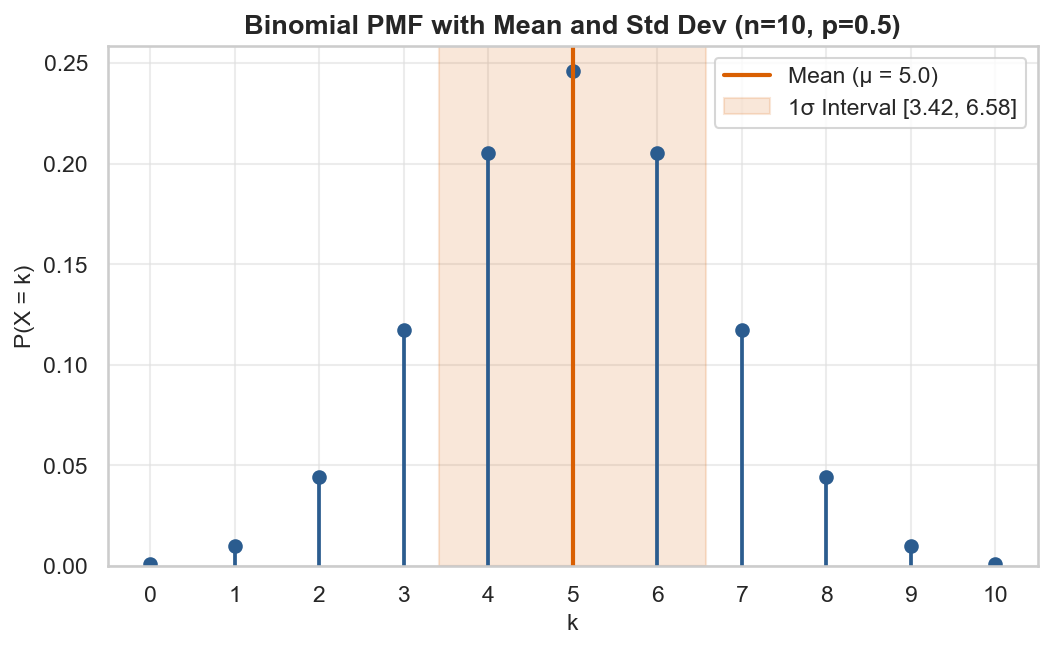

In [38]:
# Plot PMF with theoretical center and spread
fig, ax = plt.subplots()
plot_pmf(
    k_values,
    pmf_values,
    title=f"Binomial PMF with Mean and Std Dev (n={n}, p={p})",
    ax=ax,
)

# Add reference lines for Mean and 1-Std-Dev window
ax.axvline(
    mean_formula,
    color=PALETTE["secondary"],
    linestyle="-",
    linewidth=2,
    label=f"Mean (μ = {mean_formula:.1f})",
)
ax.axvspan(
    mean_formula - std_formula,
    mean_formula + std_formula,
    color=PALETTE["secondary"],
    alpha=0.15,
    label=f"1σ Interval [{mean_formula - std_formula:.2f}, {mean_formula + std_formula:.2f}]",
)

ax.legend(frameon=True)
plt.xticks(k_values)
plt.show()


## 4. Parameter Variation

The Binomial distribution is governed by two parameters: $(n, p)$.

### Effect of changing $p$ (with fixed $n$):
- **$p < 0.5$**: The probability mass shifts left. The distribution is **right-skewed** (long tail extending right toward rare high successes).
- **$p = 0.5$**: The distribution is **perfectly symmetric**.
- **$p > 0.5$**: The probability mass shifts right. The distribution is **left-skewed** (long tail extending left toward rare low successes).

### Effect of changing $n$ (with fixed $p$):
- As $n$ increases, the center moves rightward ($\mu = np$).
- The spread in absolute counts increases ($\sigma = \sqrt{np(1-p)}$).
- The distribution becomes smoother and increasingly symmetric, looking more like a continuous bell curve.


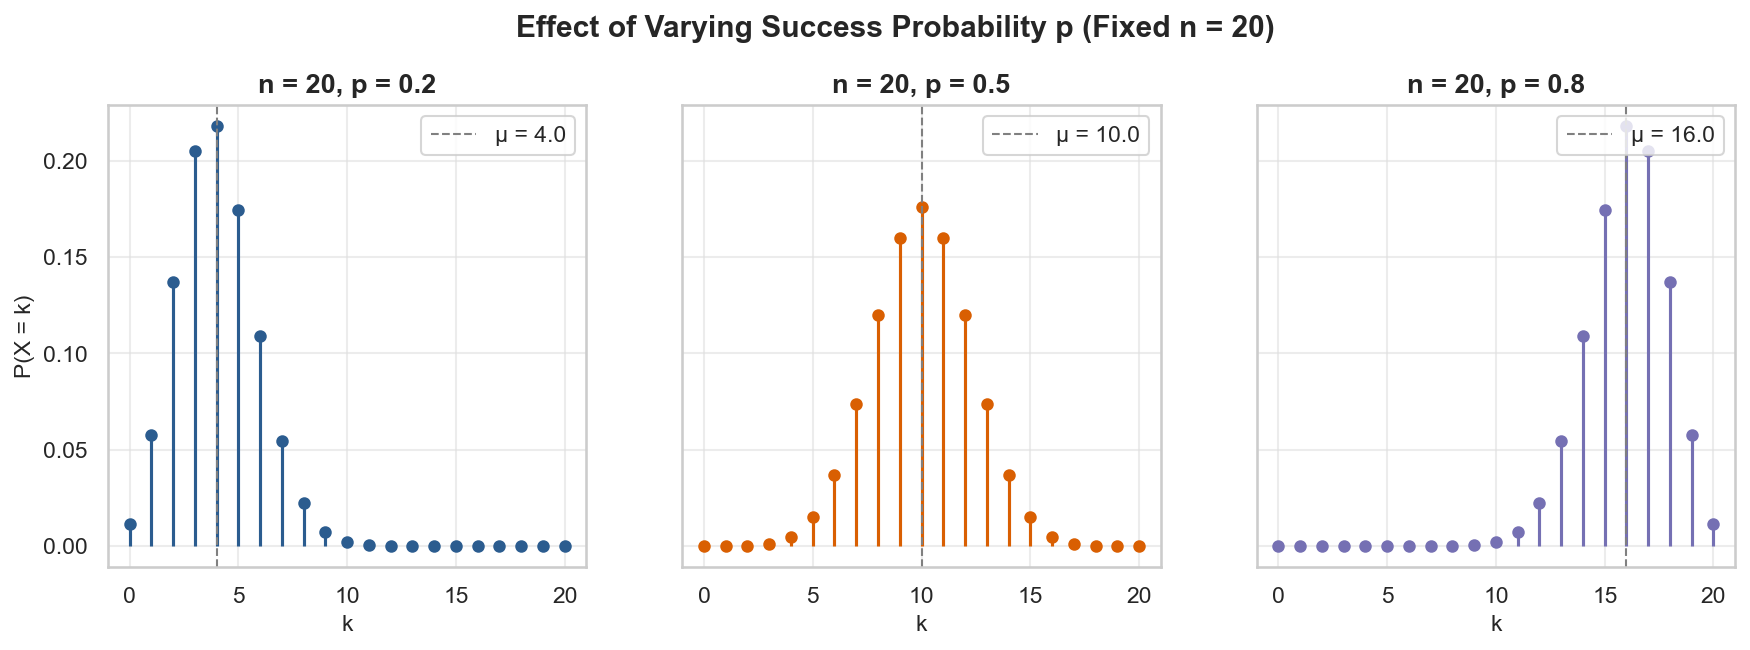

In [39]:
n_fixed = 20
p_list = [0.2, 0.5, 0.8]
colors = [PALETTE["primary"], PALETTE["secondary"], PALETTE["accent"]]

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
k_range = np.arange(0, n_fixed + 1)

for ax, p_val, col in zip(axes, p_list, colors):
    pmf = stats.binom.pmf(k_range, n_fixed, p_val)
    # Stem plot for discrete PMF
    markerline, stemlines, _ = ax.stem(k_range, pmf, basefmt=" ")
    plt.setp(markerline, color=col, markersize=5)
    plt.setp(stemlines, color=col, linewidth=1.5)

    mu = n_fixed * p_val
    ax.axvline(
        mu,
        color="gray",
        linestyle="--",
        linewidth=1,
        label=f"μ = {mu:.1f}",
    )
    ax.set_title(f"n = {n_fixed}, p = {p_val}")
    ax.set_xlabel("k")
    ax.legend(frameon=True, loc="upper right")

axes[0].set_ylabel("P(X = k)")
plt.suptitle(
    "Effect of Varying Success Probability p (Fixed n = 20)", y=1.03, weight="bold"
)
plt.show()


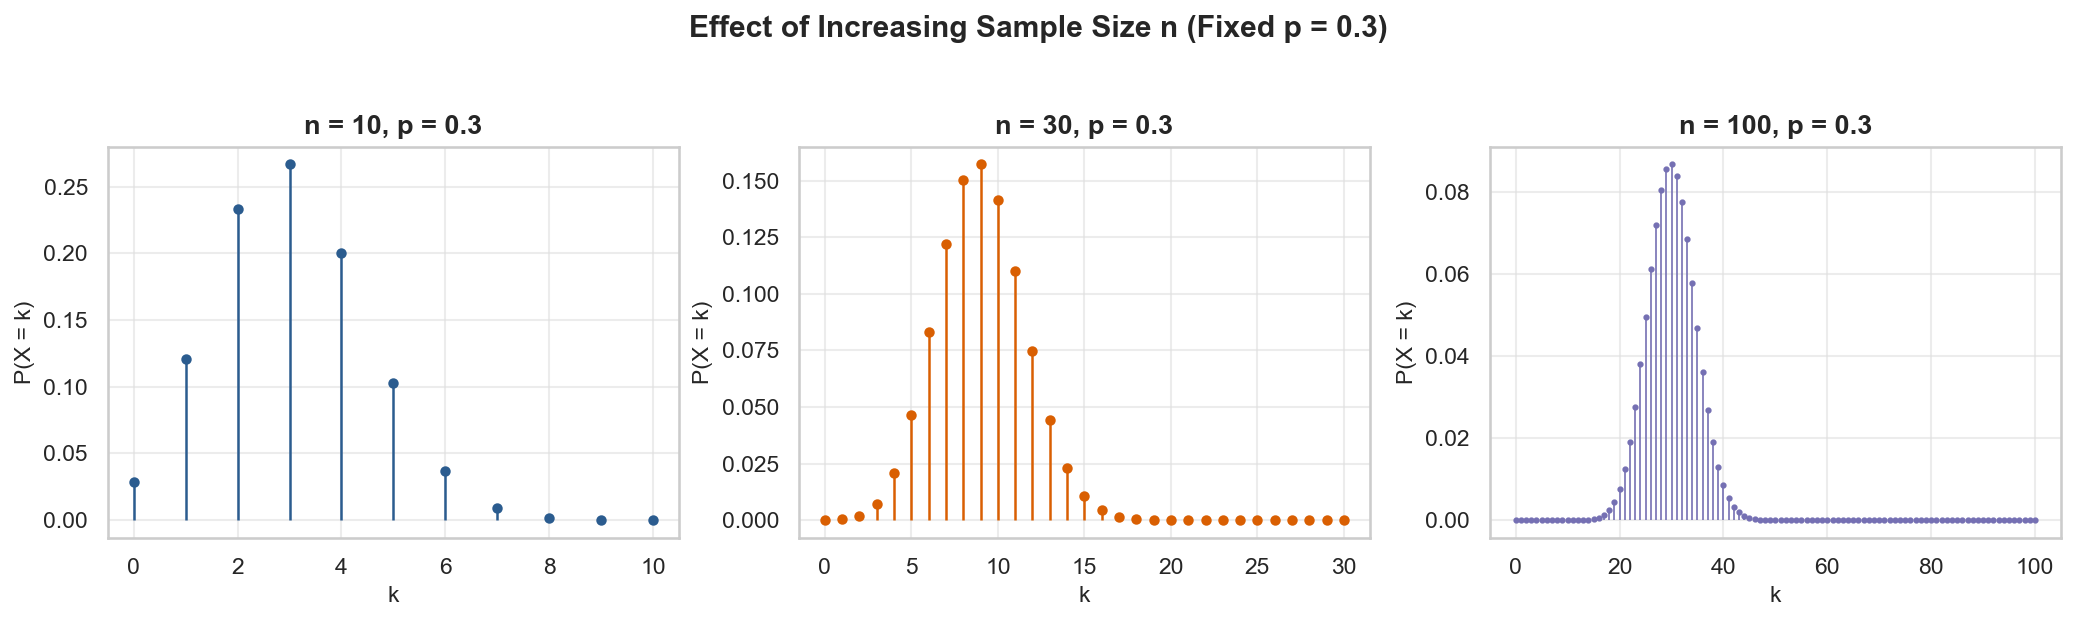

In [40]:
p_fixed = 0.3
n_list = [10, 30, 100]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, n_val, col in zip(axes, n_list, colors):
    k_vals = np.arange(0, n_val + 1)
    pmf = stats.binom.pmf(k_vals, n_val, p_fixed)

    markerline, stemlines, _ = ax.stem(k_vals, pmf, basefmt=" ")
    plt.setp(markerline, color=col, markersize=4 if n_val < 50 else 2)
    plt.setp(stemlines, color=col, linewidth=1.2 if n_val < 50 else 0.8)

    ax.set_title(f"n = {n_val}, p = {p_fixed}")
    ax.set_xlabel("k")
    ax.set_ylabel("P(X = k)")

plt.suptitle(
    "Effect of Increasing Sample Size n (Fixed p = 0.3)", y=1.03, weight="bold"
)
plt.tight_layout()
plt.show()


## 5. Simulation & Law of Large Numbers

A key strength of probability distributions is the ability to generate **synthetic data** (Monte Carlo simulation) to test algorithms or model uncertainty.

### The Law of Large Numbers (LLN)
Let $X_1, X_2, \dots, X_N$ be independent and identically distributed (i.i.d.) draws from $\text{Binomial}(n, p)$ with expected value $\mu = np$.
The sample mean is:
$$\bar{X}_N = \frac{1}{N} \sum_{i=1}^{N} X_i$$

As sample size $N \to \infty$:
1. **Convergence of the mean**: $\bar{X}_N \xrightarrow{P} \mu$ (the sample mean converges to the theoretical expected value).
2. **Convergence of the distribution**: The relative frequency of each outcome $k$ converges to its theoretical probability $P(X = k)$.


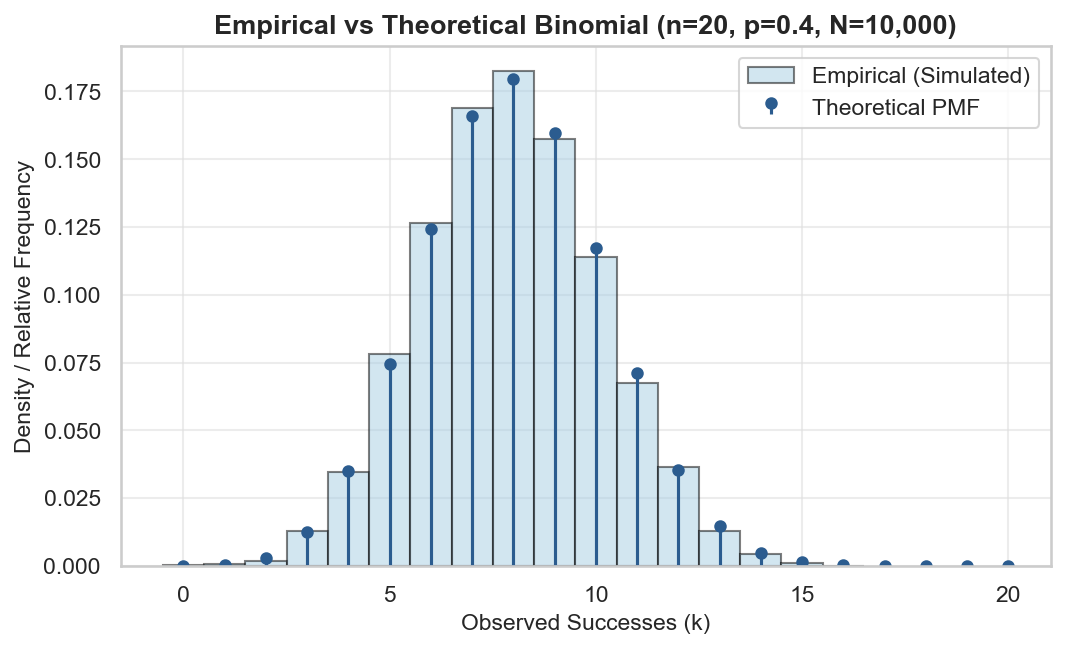

Theoretical Mean: 8.0000  |  Sample Mean: 7.9565
Theoretical Var:  4.8000  |  Sample Var:  4.7139


In [41]:
from utils.plotting import plot_sample_vs_theory

# Parameters
n_sim = 20
p_sim = 0.4
sample_size = 10000

# Generate random draws using SciPy
samples = stats.binom.rvs(n_sim, p_sim, size=sample_size, random_state=42)

# Theoretical PMF coordinates
k_theory = np.arange(0, n_sim + 1)
pmf_theory = stats.binom.pmf(k_theory, n_sim, p_sim)

# Plot empirical histogram vs theoretical stems
fig, ax = plt.subplots()
plot_sample_vs_theory(
    samples=samples,
    x_theory=k_theory,
    y_theory=pmf_theory,
    is_discrete=True,
    title=f"Empirical vs Theoretical Binomial (n={n_sim}, p={p_sim}, N={sample_size:,})",
    xlabel="Observed Successes (k)",
    ax=ax,
)
plt.show()

# Quick summary comparison
print(f"Theoretical Mean: {n_sim * p_sim:.4f}  |  Sample Mean: {np.mean(samples):.4f}")
print(
    f"Theoretical Var:  {n_sim * p_sim * (1 - p_sim):.4f}  |  Sample Var:  {np.var(samples, ddof=1):.4f}"
)


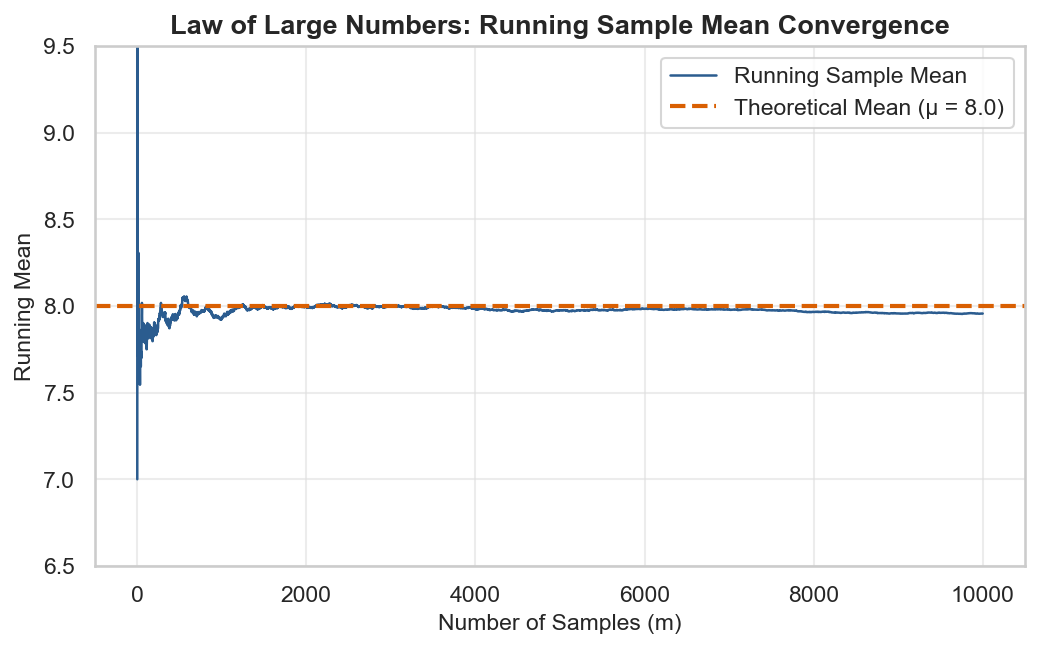

In [42]:
# Compute running cumulative average: [X1, (X1+X2)/2, (X1+X2+X3)/3, ...]
m_indices = np.arange(1, sample_size + 1)
running_mean = np.cumsum(samples) / m_indices
theoretical_mu = n_sim * p_sim

plt.figure()
plt.plot(
    m_indices,
    running_mean,
    color=PALETTE["primary"],
    linewidth=1.2,
    label="Running Sample Mean",
)
plt.axhline(
    theoretical_mu,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Theoretical Mean (μ = {theoretical_mu:.1f})",
)

plt.title("Law of Large Numbers: Running Sample Mean Convergence")
plt.xlabel("Number of Samples (m)")
plt.ylabel("Running Mean")
plt.ylim(theoretical_mu - 1.5, theoretical_mu + 1.5)
plt.legend(frameon=True)
plt.show()


## 6. Applied Real-World Use Case: Quality Control & Acceptance Sampling

### Scenario
A semiconductor factory manufactures microchips. From each production batch, quality control (QC) engineers randomly sample $n = 50$ chips for automated testing.

Under normal operating conditions, the baseline defect rate is **$p = 0.04$** (4%).

### Operational Decision Rule
- **Accept batch**: If $\le 2$ defective chips are found ($k \le 2$).
- **Reject / Hold batch**: If $> 2$ defective chips are found ($k \ge 3$).

### Questions to answer:
1. **Producer's Risk (Type I Error)**: What is the probability that a healthy batch ($p=0.04$) is rejected purely by bad luck?
2. **Consumer's Risk / Detection (Power)**: If machine wear increases the true defect rate to $p = 0.10$ (10%), how likely are we to catch and reject the bad batch?


In [43]:
n_batch = 50
p_good = 0.04  # Normal operating defect rate
threshold = 2  # Max acceptable defects

# Case 1: Healthy batch (p = 0.04)
# P(Accept) = P(X <= 2)
prob_accept_good = stats.binom.cdf(threshold, n_batch, p_good)
# P(Reject) = P(X >= 3) = P(X > 2) = 1 - P(X <= 2)
prob_reject_good = stats.binom.sf(threshold, n_batch, p_good)

# Case 2: Degraded batch (p = 0.10)
p_bad = 0.10
prob_catch_bad = stats.binom.sf(threshold, n_batch, p_bad)

print("--- QUALITY CONTROL METRICS ---")
print(f"Sample size per batch (n): {n_batch}")
print(f"Acceptance threshold: <= {threshold} defects\n")
print(f"Normal Batch (p = {p_good}):")
print(f"  P(Accept): {prob_accept_good:.4f} ({prob_accept_good*100:.1f}%)")
print(f"  P(False Rejection / Risk): {prob_reject_good:.4f} ({prob_reject_good*100:.1f}%)")
print(f"\nDegraded Batch (p = {p_bad}):")
print(f"  P(Correctly Rejecting Bad Batch): {prob_catch_bad:.4f} ({prob_catch_bad*100:.1f}%)")


--- QUALITY CONTROL METRICS ---
Sample size per batch (n): 50
Acceptance threshold: <= 2 defects

Normal Batch (p = 0.04):
  P(Accept): 0.6767 (67.7%)
  P(False Rejection / Risk): 0.3233 (32.3%)

Degraded Batch (p = 0.1):
  P(Correctly Rejecting Bad Batch): 0.8883 (88.8%)


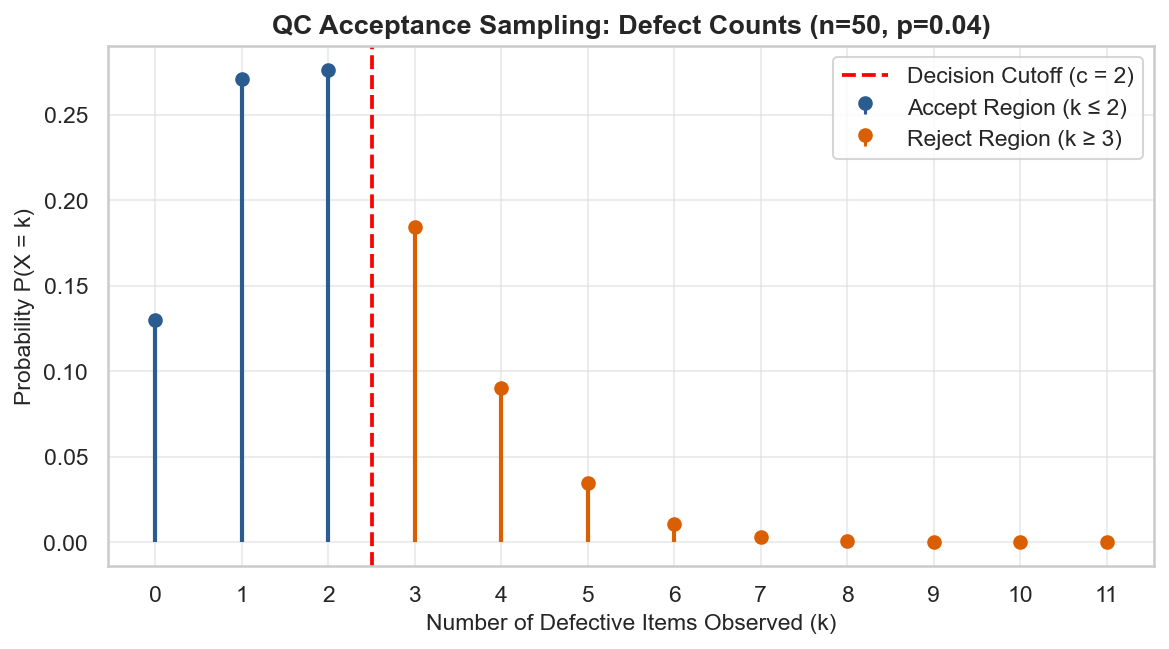

In [44]:
k_batch = np.arange(0, 12)  # Focus on realistic range of defect counts
pmf_good = stats.binom.pmf(k_batch, n_batch, p_good)

fig, ax = plt.subplots(figsize=(9, 4.5))

# Plot Accepted region (k <= 2) in primary blue
mask_accept = k_batch <= threshold
marker_acc, stem_acc, _ = ax.stem(
    k_batch[mask_accept], pmf_good[mask_accept], basefmt=" ", label="Accept Region (k ≤ 2)"
)
plt.setp(marker_acc, color=PALETTE["primary"], markersize=6)
plt.setp(stem_acc, color=PALETTE["primary"], linewidth=2)

# Plot Rejected region (k >= 3) in warning red/secondary
mask_reject = k_batch > threshold
marker_rej, stem_rej, _ = ax.stem(
    k_batch[mask_reject], pmf_good[mask_reject], basefmt=" ", label="Reject Region (k ≥ 3)"
)
plt.setp(marker_rej, color=PALETTE["secondary"], markersize=6)
plt.setp(stem_rej, color=PALETTE["secondary"], linewidth=2)

# Threshold dividing line
ax.axvline(
    threshold + 0.5,
    color="red",
    linestyle="--",
    linewidth=1.8,
    label=f"Decision Cutoff (c = {threshold})",
)

ax.set_title(f"QC Acceptance Sampling: Defect Counts (n={n_batch}, p={p_good})")
ax.set_xlabel("Number of Defective Items Observed (k)")
ax.set_ylabel("Probability P(X = k)")
ax.set_xticks(k_batch)
ax.legend(frameon=True)
plt.show()


## 7. Parameter Estimation (Maximum Likelihood Estimation - MLE)

In practical data science, we rarely know the true parameter $p$. Instead, we observe data and must **estimate** $p$.

### The Likelihood Function
Suppose we observe $N$ independent batches of size $n$, with observed success counts $k_1, k_2, \dots, k_N$.
The **likelihood** $L(p)$ is the joint probability of observing our exact sample as a function of the candidate parameter $p$:
$$L(p) = \prod_{i=1}^{N} \binom{n}{k_i} p^{k_i} (1 - p)^{n - k_i}$$

### Log-Likelihood & Analytical Derivation
Because products are computationally unstable and difficult to differentiate, we maximize the **log-likelihood** $\ln L(p)$:
$$\ln L(p) = \sum_{i=1}^{N} \ln \binom{n}{k_i} + \left(\sum_{i=1}^N k_i\right) \ln p + \left(N n - \sum_{i=1}^N k_i\right) \ln(1 - p)$$

Taking the derivative with respect to $p$ and setting it to 0 gives the **MLE estimator**:
$$\frac{d}{dp} \ln L(p) = \frac{\sum k_i}{p} - \frac{N n - \sum k_i}{1 - p} = 0 \implies \hat{p}_{\text{MLE}} = \frac{\sum_{i=1}^{N} k_i}{N \cdot n} = \frac{\bar{k}}{n}$$
The MLE is simply the total observed successes divided by the total number of individual trials!


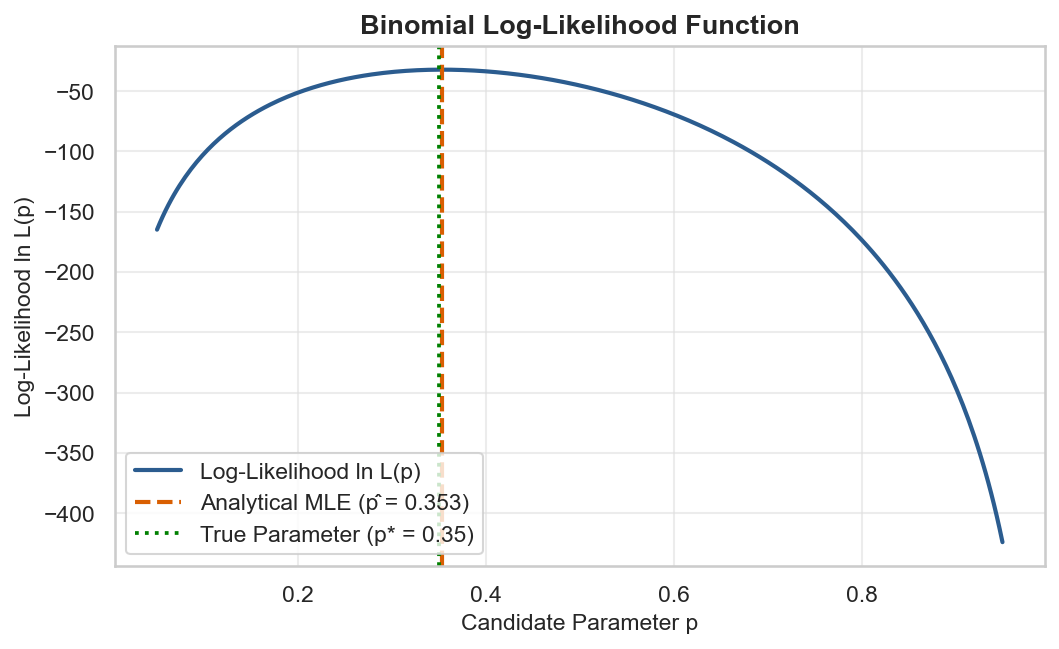

In [45]:
# True unknown process parameter
p_true = 0.35
n_trials = 20  # Trials per batch
N_obs = 15  # Number of observed batches

# Generate synthetic observed data
observed_k = stats.binom.rvs(n_trials, p_true, size=N_obs, random_state=101)

# Analytical MLE formula: Total successes / Total trials
total_successes = np.sum(observed_k)
total_trials = N_obs * n_trials
p_mle_analytical = total_successes / total_trials


# Define log-likelihood function for an array of candidate p values
def binomial_log_likelihood(p_candidate, k_data, n):
    # Sum log PMFs across all observations
    return np.sum([stats.binom.logpmf(k_data, n, p) for p in p_candidate], axis=1)


p_grid = np.linspace(0.05, 0.95, 300)
log_lik = binomial_log_likelihood(p_grid, observed_k, n_trials)

# Plot Log-Likelihood Curve
plt.figure()
plt.plot(
    p_grid,
    log_lik,
    color=PALETTE["primary"],
    linewidth=2,
    label="Log-Likelihood ln L(p)",
)
plt.axvline(
    p_mle_analytical,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Analytical MLE (p̂ = {p_mle_analytical:.3f})",
)
plt.axvline(
    p_true,
    color="green",
    linestyle=":",
    linewidth=1.8,
    label=f"True Parameter (p* = {p_true:.2f})",
)

plt.title("Binomial Log-Likelihood Function")
plt.xlabel("Candidate Parameter p")
plt.ylabel("Log-Likelihood ln L(p)")
plt.legend(frameon=True)
plt.show()


In [46]:
from scipy.optimize import minimize


# Negative log-likelihood objective function for optimizer
def neg_log_likelihood(p, k_data, n):
    # Clip p to stay strictly inside open interval (0, 1)
    p = np.clip(p[0], 1e-6, 1 - 1e-6)
    return -np.sum(stats.binom.logpmf(k_data, n, p))


# Minimize NLL starting from initial guess p = 0.5
res = minimize(
    neg_log_likelihood, x0=[0.5], args=(observed_k, n_trials), bounds=[(1e-4, 0.9999)]
)
p_mle_numerical = res.x[0]

# Standard Error of MLE: sqrt(p * (1 - p) / (N * n))
se_mle = np.sqrt(p_mle_numerical * (1 - p_mle_numerical) / total_trials)
ci_lower = p_mle_numerical - 1.96 * se_mle
ci_upper = p_mle_numerical + 1.96 * se_mle

print("--- MAXIMUM LIKELIHOOD ESTIMATION RESULTS ---")
print(f"True Parameter (p*):        {p_true:.4f}")
print(f"Analytical MLE (p̂):         {p_mle_analytical:.4f}")
print(f"Numerical MLE (Optimizer):  {p_mle_numerical:.4f}")
print(f"Standard Error (SE):        {se_mle:.4f}")
print(f"95% Confidence Interval:    [{ci_lower:.4f}, {ci_upper:.4f}]")


--- MAXIMUM LIKELIHOOD ESTIMATION RESULTS ---
True Parameter (p*):        0.3500
Analytical MLE (p̂):         0.3533
Numerical MLE (Optimizer):  0.3533
Standard Error (SE):        0.0276
95% Confidence Interval:    [0.2992, 0.4074]


## 8. Related Distributions & Summary

The Binomial distribution sits at the heart of discrete probability, directly linking to several other key distributions:

1. **Bernoulli Distribution**:
   - The special case where $n = 1$: $\text{Bernoulli}(p) \equiv \text{Binomial}(1, p)$.
   - A Binomial variable is the sum of $n$ independent and identically distributed Bernoulli variables: $X = \sum_{i=1}^n B_i$.

2. **Poisson Distribution (Law of Rare Events)**:
   - When the number of trials $n$ is large and the success probability $p$ is small such that $\lambda = n p$ is moderate, the Binomial distribution converges to the Poisson:
     $$\lim_{n \to \infty, p \to 0} \text{Binomial}(n, p) = \text{Poisson}(\lambda = np)$$
   - **Rule of thumb**: A Poisson approximation is very accurate when $n \ge 20$ and $p \le 0.05$ (or $n \ge 100$ and $np \le 10$).

3. **Normal Distribution (Central Limit Theorem / de Moivre-Laplace)**:
   - When $n$ is large and both $np \ge 5$ and $n(1-p) \ge 5$, the Binomial distribution is well approximated by a continuous Normal distribution:
     $$\text{Binomial}(n, p) \approx \mathcal{N}\big(\mu = np, \, \sigma^2 = np(1-p)\big)$$

4. **Negative Binomial & Geometric Distributions**:
   - Binomial fixes the number of trials $n$ and counts the number of successes $k$.
   - **Geometric** and **Negative Binomial** fix the required number of successes and count the number of trials (or failures) needed to achieve them.

5. **Hypergeometric Distribution**:
   - Binomial assumes sampling *with replacement* (or an infinite population), so $p$ remains constant.
   - Hypergeometric models sampling *without replacement* from a finite population.


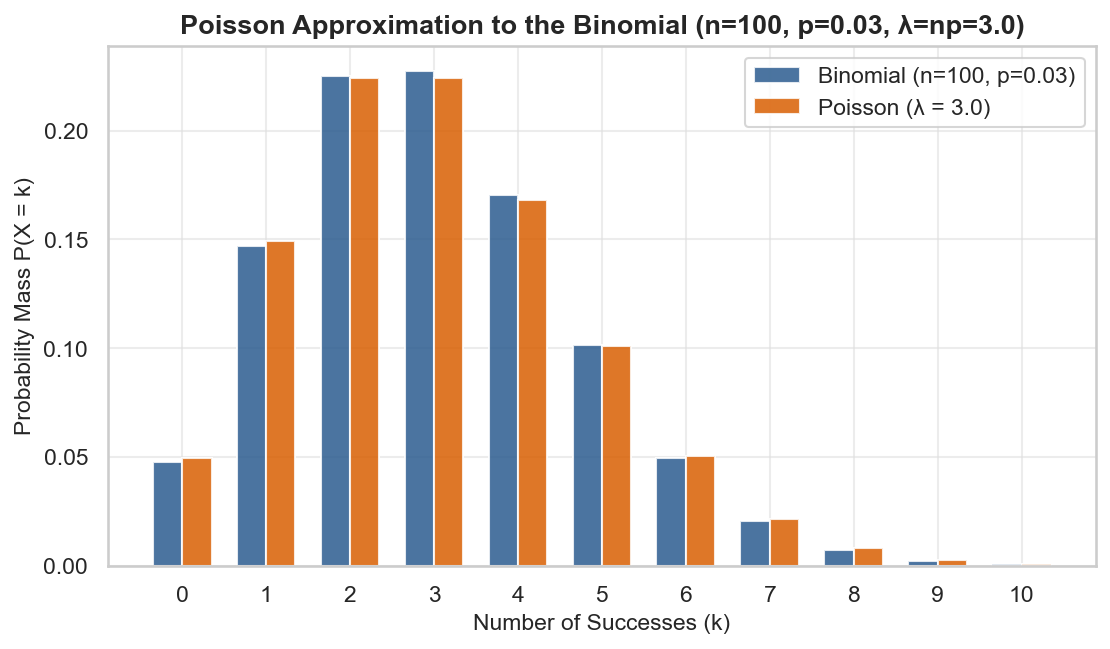

In [47]:
# Parameters for rare-event setting: large n, small p
n_approx = 100
p_approx = 0.03
lambda_param = n_approx * p_approx  # lambda = np = 3.0

k_vals = np.arange(0, 11)

# Theoretical probabilities under both distributions
binom_probs = stats.binom.pmf(k_vals, n_approx, p_approx)
poisson_probs = stats.poisson.pmf(k_vals, lambda_param)

# Plot comparison
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bar_width = 0.35

ax.bar(
    k_vals - bar_width / 2,
    binom_probs,
    width=bar_width,
    label=f"Binomial (n={n_approx}, p={p_approx})",
    color=PALETTE["primary"],
    alpha=0.85,
)
ax.bar(
    k_vals + bar_width / 2,
    poisson_probs,
    width=bar_width,
    label=f"Poisson (λ = {lambda_param:.1f})",
    color=PALETTE["secondary"],
    alpha=0.85,
)

ax.set_title(
    f"Poisson Approximation to the Binomial (n={n_approx}, p={p_approx}, λ=np={lambda_param:.1f})"
)
ax.set_xlabel("Number of Successes (k)")
ax.set_ylabel("Probability Mass P(X = k)")
ax.set_xticks(k_vals)
ax.legend(frameon=True)
plt.show()


### Summary Card: Binomial Distribution

| Property | Formulation |
| :--- | :--- |
| **Notation** | $X \sim \text{Binomial}(n, p)$ |
| **Parameters** | $n \in \{1, 2, \dots\}$ (number of trials), $p \in [0, 1]$ (success probability) |
| **Support** | $k \in \{0, 1, 2, \dots, n\}$ |
| **PMF** | $P(X = k) = \binom{n}{k} p^k (1 - p)^{n - k}$ |
| **CDF** | $F(k) = \sum_{i=0}^{\lfloor k \rfloor} \binom{n}{i} p^i (1 - p)^{n - i}$ |
| **Mean ($\mu$)** | $n p$ |
| **Variance ($\sigma^2$)** | $n p (1 - p)$ |
| **Skewness ($\gamma_1$)** | $\frac{1 - 2p}{\sqrt{n p (1 - p)}}$ |
| **Excess Kurtosis ($\gamma_2$)** | $\frac{1 - 6p(1 - p)}{n p (1 - p)}$ |
| **MLE Estimator** | $\hat{p} = \frac{\sum k_i}{N \cdot n} = \frac{\bar{k}}{n}$ |
| **Key Use Cases** | Quality control, conversion rates, polling, binary classification metrics |
